### Feature engineering 

In [5]:
import time
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, median_absolute_error, mean_absolute_percentage_error)
from xgboost import XGBRegressor

In [2]:

df = pd.read_csv('../../data/prepared_energy_dataset.csv')
target_B = 'Predicted_Energy_Requirement_kWh'

cols_to_drop = [
    'Throughput_Mbps',
    'Record_ID', 'Timestamp', 'split', 'Month',
    'Energy_Management_Status',
    'Energy_Consumption_kWh', 'Energy_Efficiency_Mbps_per_kWh', 
    'Carbon_Emission_kg', 'Operational_Cost_USD',
    'Network_Condition', 'Congestion_Index', 'QoS_Satisfaction_Score', 
    'SLA_Violation_Count', 'Future_Congestion_Index'
]


df_final = df.drop(columns=cols_to_drop, errors='ignore')
train_df = df_final[df['split'] == 'train']
val_df = df_final[df['split'] == 'val']
test_df = df_final[df['split'] == 'test']

X_train, y_train = train_df.drop(columns=[target_B]), train_df[target_B]
X_val, y_val = val_df.drop(columns=[target_B]), val_df[target_B]
X_test, y_test = test_df.drop(columns=[target_B]), test_df[target_B]

print(f"Task B Training Features: {X_train.shape[1]}")

Task B Training Features: 33


### Baseline model

In [6]:
def print_metrics(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    rmse_pct = (rmse / y_true.mean()) * 100
    mape_pct = mean_absolute_percentage_error(y_true, y_pred) * 100
    
    print(f"{model_name:38} | MAE: {mae:.4f} | MSE: {mse:.5f} | RMSE: {rmse:.4f} | R2: {r2:6.4f} | RMSE (Norm): {rmse_pct:5.1f}% | MAPE: {mape_pct:5.1f}%")

print("--- Task B Baselines (Validation Set) ---\n")

mean_model = DummyRegressor(strategy="mean")
mean_model.fit(X_train, y_train)
mean_preds = mean_model.predict(X_val)
print_metrics("Mean baseline", y_val, mean_preds)

current_kwh_val = X_val['Total_Power_Watt'] / 12000
print_metrics("Persistence (current kWh)", y_val, current_kwh_val)

peak_col = 'peak_next' if 'peak_next' in X_train.columns else 'Peak_Time'

traffic_means = X_train.groupby(peak_col)['Traffic_Volume_Mbps'].mean()
print(f"\nRegime means of next-slot traffic (Mbps): {traffic_means.round(0).to_dict()}")

predicted_next_traffic = X_val[peak_col].map(traffic_means)
current_kwh_per_mbps = current_kwh_val / np.maximum(X_val['Traffic_Volume_Mbps'], 1)
regime_preds = predicted_next_traffic * current_kwh_per_mbps

print_metrics("Regime baseline (calendar x kWh/Mbps)", y_val, regime_preds)

--- Task B Baselines (Validation Set) ---

Mean baseline                          | MAE: 0.1055 | MSE: 0.02680 | RMSE: 0.1637 | R2: -0.0004 | RMSE (Norm):  99.1% | MAPE: 124.0%
Persistence (current kWh)              | MAE: 0.1046 | MSE: 0.03136 | RMSE: 0.1771 | R2: -0.1704 | RMSE (Norm): 107.2% | MAPE:  92.6%

Regime means of next-slot traffic (Mbps): {0: 2856.0, 1: 4886.0}
Regime baseline (calendar x kWh/Mbps)  | MAE: 0.0765 | MSE: 0.01381 | RMSE: 0.1175 | R2: 0.4845 | RMSE (Norm):  71.2% | MAPE:  75.8%


### Advanced model

In [7]:
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X_train.select_dtypes(exclude=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), numerical_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_cols)
])

xgb_base = XGBRegressor(random_state=42)

raw_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb_base)
])

log_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', TransformedTargetRegressor(regressor=xgb_base, func=np.log1p, inverse_func=np.expm1))
])

raw_pipeline.fit(X_train, y_train)
log_pipeline.fit(X_train, y_train)

raw_preds = raw_pipeline.predict(X_val)
log_preds = log_pipeline.predict(X_val)

def print_metrics(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    medae = median_absolute_error(y_true, y_pred)
    
    rmse_pct = (rmse / y_true.mean()) * 100
    mape_pct = mean_absolute_percentage_error(y_true, y_pred) * 100
    print(f"{name:30} | MAE: {mae:.4f} | MSE: {mse:.5f} | RMSE: {rmse:.4f} | R2: {r2:6.4f} | RMSE (Norm): {rmse_pct:5.1f}% | MAPE: {mape_pct:5.1f}%")
    
    return mae

print("\n--- Target Transformation Comparison ---")
raw_mae = print_metrics("Raw Target", y_val, raw_preds)
log_mae = print_metrics("Log Target (back-transformed)", y_val, log_preds)

use_log = log_mae < (raw_mae * 0.99)
print(f"\nUse log target: {use_log} (rule: only if validation MAE is at least 1% lower!)")

/var/folders/t9/5qyb5pw554s_w_jt9c13myrh0000gn/T/ipykernel_77111/2195955219.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()



--- Target Transformation Comparison ---
Raw Target                     | MAE: 0.0825 | MSE: 0.01592 | RMSE: 0.1262 | R2: 0.4059 | RMSE (Norm):  76.4% | MAPE:  81.0%
Log Target (back-transformed)  | MAE: 0.0816 | MSE: 0.01616 | RMSE: 0.1271 | R2: 0.3968 | RMSE (Norm):  77.0% | MAPE:  80.1%

Use log target: True (rule: only if validation MAE is at least 1% lower!)


### Hyperparameter tuning 

In [9]:
tscv = TimeSeriesSplit(n_splits=4)
models_to_tune_B = {
    'Ridge': (
        Pipeline([('prep', preprocessor), ('reg', Ridge())]), 
        {'reg__alpha': [0.1, 1, 10, 100, 1000]}, 
        5
    ),
    'XGBoost (Direct)': (
        Pipeline([('prep', preprocessor), ('reg', XGBRegressor(random_state=42))]), 
        {
            'reg__n_estimators': [100, 200, 300], 
            'reg__max_depth': [2, 3, 4, 6], 
            'reg__learning_rate': [0.02, 0.05, 0.1],
            'reg__subsample': [0.7, 0.9, 1.0],
            'reg__colsample_bytree': [0.6, 0.8, 1.0],
            'reg__min_child_weight': [1, 5, 20],
            'reg__reg_lambda': [1, 5, 20]
        }, 
        12
    )
}

start_time = time.time()
best_models_B = {}

for name, (pipe, params, n_iter) in models_to_tune_B.items():
    print(f"Tuning {name}...")
    search = RandomizedSearchCV(
        estimator=pipe, param_distributions=params, n_iter=n_iter,
        scoring='neg_mean_absolute_error', cv=tscv, random_state=42, n_jobs=-1
    )
    search.fit(X_train, y_train)
    best_models_B[name] = search.best_estimator_
    best_cv_mae = -search.best_score_
    clean_params = {k.replace('reg__', ''): v for k, v in search.best_params_.items()}
    print(f"CV MAE: {best_cv_mae:.4f} kWh | Params = {clean_params}")
    val_preds = search.best_estimator_.predict(X_val)
    print_metrics(f"{name} (Validation)", y_val, val_preds)
    print("-" * 80) # Visual separator

print(f"\nTuning time: {time.time() - start_time:.0f} seconds")

Tuning Ridge...
CV MAE: 0.0851 kWh | Params = {'alpha': 1000}
Ridge (Validation)             | MAE: 0.0898 | MSE: 0.01965 | RMSE: 0.1402 | R2: 0.2666 | RMSE (Norm):  84.9% | MAPE:  94.2%
--------------------------------------------------------------------------------
Tuning XGBoost (Direct)...
CV MAE: 0.0755 kWh | Params = {'subsample': 0.7, 'reg_lambda': 20, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.02, 'colsample_bytree': 0.8}
XGBoost (Direct) (Validation)  | MAE: 0.0788 | MSE: 0.01437 | RMSE: 0.1199 | R2: 0.4637 | RMSE (Norm):  72.6% | MAPE:  82.6%
--------------------------------------------------------------------------------

Tuning time: 2 seconds


### Validation and Evaluation

In [10]:
X_train_val = pd.concat([X_train, X_val], ignore_index=True)
y_train_val = pd.concat([y_train, y_val], ignore_index=True)

final_model_B = best_models_B['XGBoost (Direct)']

print("Refitting XGBoost on combined Train+Val data...")
final_model_B.fit(X_train_val, y_train_val)

test_preds_B = final_model_B.predict(X_test)

mae = mean_absolute_error(y_test, test_preds_B)
mse = mean_squared_error(y_test, test_preds_B)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, test_preds_B)
medae = median_absolute_error(y_test, test_preds_B)
rmse_pct = (rmse / y_test.mean()) * 100
mape_pct = mean_absolute_percentage_error(y_test, test_preds_B) * 100

print("\n--- Final Test Set Performance (XGBoost Direct) ---")
print(f"MAE:   {mae:.4f} kWh")
print(f"MSE:   {mse:.5f} kWh^2")
print(f"RMSE:  {rmse:.4f} kWh")
print(f"RMSE (Normalized): {rmse_pct:.1f}%")
print(f"R2:    {r2:.4f}")
print(f"MedAE: {medae:.4f} kWh")
print(f"MAPE:  {mape_pct:.1f}%")

Refitting XGBoost on combined Train+Val data...

--- Final Test Set Performance (XGBoost Direct) ---
MAE:   0.0746 kWh
MSE:   0.01242 kWh^2
RMSE:  0.1114 kWh
RMSE (Normalized): 68.8%
R2:    0.4502
MedAE: 0.0526 kWh
MAPE:  76.4%


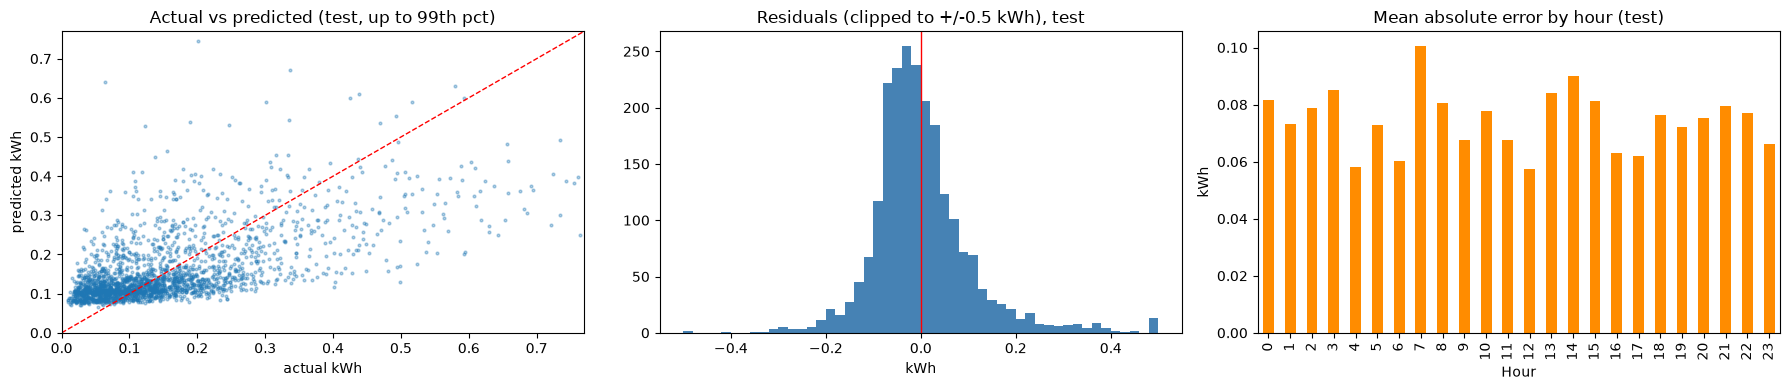

Share of test rows with |error| > 0.3 kWh: 2.6%


In [11]:
import matplotlib.pyplot as plt
residuals_B = y_test - test_preds_B
abs_error_B = np.abs(residuals_B)

lim99 = np.quantile(y_test, 0.99)
test_hours = pd.to_datetime(df[df['split'] == 'test']['Timestamp']).dt.hour

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

ax[0].scatter(y_test, test_preds_B, s=4, alpha=0.35)
ax[0].plot([0, lim99], [0, lim99], 'r--', lw=1)
ax[0].set_xlim(0, lim99)
ax[0].set_ylim(0, lim99)
ax[0].set_title('Actual vs predicted (test, up to 99th pct)')
ax[0].set_xlabel('actual kWh')
ax[0].set_ylabel('predicted kWh')

clipped_residuals = np.clip(residuals_B, -0.5, 0.5)
ax[1].hist(clipped_residuals, bins=50, color='steelblue')
ax[1].axvline(0, color='r', lw=1)
ax[1].set_title('Residuals (clipped to +/-0.5 kWh), test')
ax[1].set_xlabel('kWh')
error_df_B = pd.DataFrame({'Hour': test_hours.values, 'Absolute_Error': abs_error_B.values})
mae_by_hour = error_df_B.groupby('Hour')['Absolute_Error'].mean()
mae_by_hour.plot(kind='bar', ax=ax[2], color='darkorange')
ax[2].set_title('Mean absolute error by hour (test)')
ax[2].set_ylabel('kWh')

plt.tight_layout()
plt.show()

large_errors = abs_error_B > 0.3
pct_large = large_errors.mean() * 100
print(f"Share of test rows with |error| > 0.3 kWh: {pct_large:.1f}%")

Calculating permutation importance for Task B...


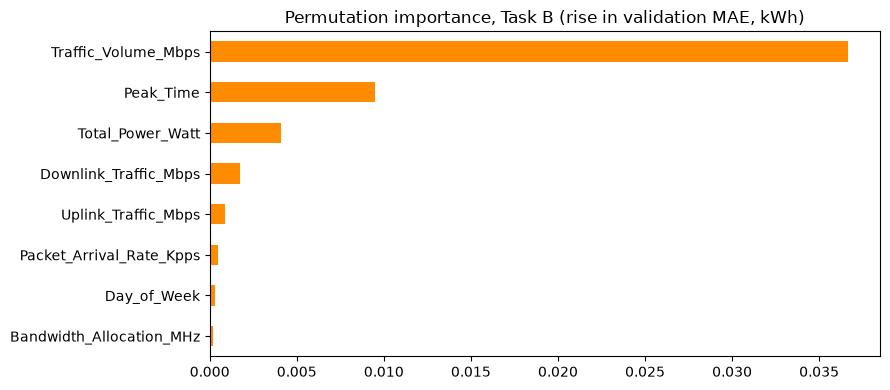

In [12]:
print("Calculating permutation importance for Task B...")
pi_B = permutation_importance(final_model_B, X_val, y_val, scoring='neg_mean_absolute_error', n_repeats=5, random_state=42, n_jobs=-1)

importance_df_B = pd.Series(pi_B.importances_mean, index=X_val.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
importance_df_B.head(8).sort_values(ascending=True).plot(kind='barh', ax=ax, color='darkorange')
ax.set_title('Permutation importance, Task B (rise in validation MAE, kWh)')
plt.tight_layout()
plt.show()